# Feature Extraction with Pretrained Model 

This Jupyter Notebook contains an image recognition model that uses feature maps that are extracted using a pretrained `VGG16` model instead of original images for training and prediction making. The model is trained to recognize four different types of dinnerware items from images. The model is created using the `Keras` library with `TesnsorFlow` as the backend. 

`Matplotlib.pyplot` and `NumPy` libraries are used for formatting and visualising data and performance results. `Time` library provides a method for measuring the model's training time. The `Scikit Learn` library is used to calculate performance metrics and also to display them more visually.

In [32]:
import os, shutil, pathlib
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
import time

keras.utils.set_random_seed(2)

Using the `keras.utils.set_random_seed` function reduces the difference between different runs so that performance results are more similar if the model is created and trained again. 

## Data Preprocessing

The dataset used for the training contains images of four different types of dinnerware items: bowls, drinking glasses, mugs and plates. The images were preprocessed using Python wiht function from the `Pillow (PIL)` library. The images were cropped, resized, converted to RGB and renamed with code. For a more detailed description of the dataset refer to the `Assignment2_raport.ipynb` notebook.

The dataset is fetched from the base folder using the `pathlib.Path` class and Keras library's `image_dataset_from_directory` function. For the function to work correctly the dinnerware images need to be divided in their own folders with aproriate class names. The function is used three times to get subsets for training, validation and testing. The `batch_size` is 32 and `image_size` is 224x224 pixels. The `seed` parameter ensures that the initial shuffle of the datasets is always the same increasing reproducbility.

In [33]:
base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=True,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)

for data_batch, labels_batch in train_dataset:
    print("Data batch shape:", data_batch.shape)
    print("Labels batch shape:", labels_batch.shape)
    break

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.
Data batch shape: (32, 224, 224, 3)
Labels batch shape: (32,)


The training set has 296 images, the validation set has 93 images and the test set has 95 images. A batch has 32 images wiht 224 x 224 dimension and they are RGB colour images that contain three colour channels. This explains the batch shape: (32, 224, 224, 3).

Below are some examples of the images in the training dataset with their labels or class names.

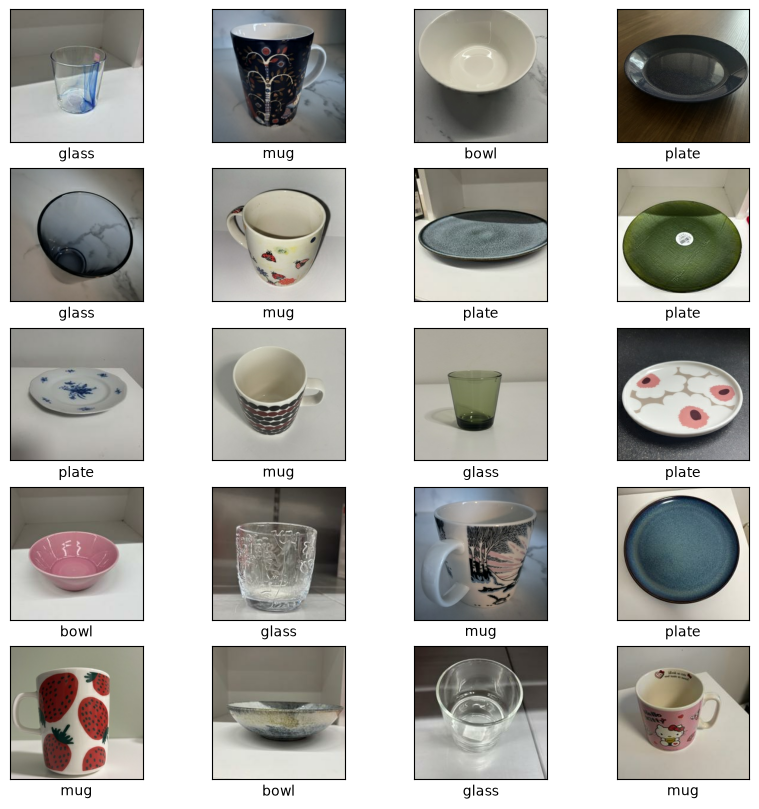

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

## Modeling: Feature Extraction

In [35]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3))
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images)
        features = conv_base.predict(preprocessed_images)
        all_features.append(features)
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)

train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

train_features.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


(296, 7, 7, 512)

In [78]:
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.15)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)          │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_7 (Flatten)                  │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_44 (Dense)                     │ (None, 64)                  │       1,605,696 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_27 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_45 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_28 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_46 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_47 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_29 (Dropout)                 │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_48 (Dense)                     │ (None, 4)                   │              68 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,612,532 (6.15 MB)

 Trainable params: 1,612,532 (6.15 MB)

 Non-trainable params: 0 (0.00 B)

## Compile and Train Model

In [79]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [80]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction.keras",
        save_best_only=True,
        monitor="val_accuracy"),
        keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=10, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_features, train_labels,
    epochs=50,
    validation_data=(val_features, val_labels),
    callbacks=callbacks,
    verbose=0)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Training time: 11.9 s


## Learning Curves

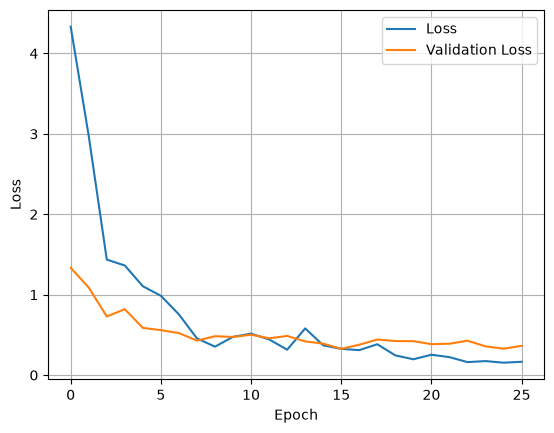

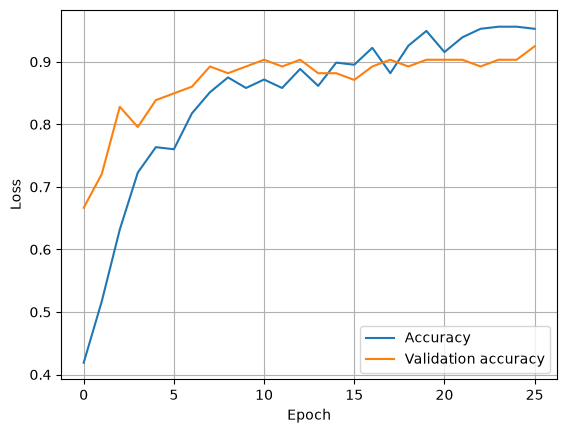

In [81]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

In [82]:
val_model = keras.models.load_model("feature_extraction.keras")
val_loss, val_acc = val_model.evaluate(val_features, val_labels)

print(f"Validation accuracy: {val_acc:.3f}")
print(f"Validation loss: {val_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9247 - loss: 0.3636 
Validation accuracy: 0.925
Validation loss: 0.364


## Version Testing

Jotain ajatuksia:
- Validation scoret on mitattu mallista jonka validation loss oli paras
- Tulokset voivat muuttua jos feature extraction tehdään uudelleen ja malli koulutetaan uudelleen, erityisesti kun training setissä on shuffle päällä
- Testien validation tulosten perusteella Version 4 valittiin lopulliseksi malliksi

| Test            | Modification                                                                | Validation accuracy (%) | Validation loss |  Training time (top layers) (s) | Conclusions          |
| --------------- | --------------------------------------------------------------------------- | ------------------------| --------------- | ------------------------------- | -------------------- |
| Original model  |                                                                             | 86.0                    | 0.420           | 4.7                             | The validation accuracy score is already fairly high. The validation accuracy and loss scores seem to stabilize quite fast meaning that the model does not learn much more after the first five epochs or so. |
| Version 1       | Added Dense(32) layer                                                       | 90.3                    | 0.266           | 4.9                             | The validation accuracy is slightly better. The validation accuracy scores seem to not getter much better after the 5th epoch. The validation loss scores seem to get a bit worse at later epochs which could indicate overfitting.  |
| Original model  | Remove Dense(32) layer, and set learning rate to 0.001                      | 92.5                    | 0.268           | 4.2                             | The validation accuracy and  loss scores seem to better but no other noticeable difference when compared to the first test.|
| Version 3       | Split Dense(156) layer into smaller layers, change GlobalAveragePooling2D layer into Flatten(), update and add Dropout() layers| 88.17        | 0.458     | 8.2    | The validation and accuracy scores seem to still stabilize quickly and the fluctuate a lot more. The model seems to struggles to learn. Training time is slightly longer.   |
| Version 4       | Add Dropout(0.15) layer                                                     | 94.6                    | 0.174           | 15.3               | The validation accuracy is better than before and the scores look a little better overall though they drop a little in later epochs. The accuracy loss seems to be a lot better than before. Training was slower.          |
| Version 5       | Simplify model                                                              | 91.4                    | 0.313           | 9.3                | The validation accuracy and loss got slightly worse compared to the previous test and they fluctuate a little. There are some early signs of overfitting.              |
| Version 6       | Add a Dropout() layer                                                       | 90.3                    | 0.302           | 8.4                | No much difference compared to he previous test. The validation accuracy scores stabilize quickly. There is less fluctuation wiht both validation accuracy and loss scores.               |
| Version 7       | Add Dense() and Dropout() layers to the originl model                       | 92.3                    | 0.135           | 7.2                | The accuracy is not much better but the loss is better compared to the previous. The accuracy scores seem to stabilize really early and do not get much better after the 5th epoch. Similar pattern can be seen with the loss scores.               |

**Original model**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.GlobalAveragePooling2D()(inputs) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 2**<br>
**Added Dense(32) layer**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.GlobalAveragePooling2D()(inputs) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 3**<br>
**Split Dense(256), change to Flatten(), Dropout(0.2) and Dropout(0.1)**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**FINAL VERSION**<br>
**Version 4**<br>
**Added Dropout(0.15) layer**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.15)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 5**<br>
**Simplify model (remove layers)**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 6**<br>
**Add Dense(16) layer**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(16, activation="relu")(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 7**</br>
```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.GlobalAveragePooling2D()(inputs) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

## Test Performance

The final version of model that was chosen based on the validation results needs to be tested to make sure the validation results are reliable. The model should be able to achieve similar results with the test data, otherwise the model must be deemed unreliable and unsuitable for this this task.

The best version, meaning the epoch run with the lowest validation loss score, of the final model was saved with ModelCheckpoint callback into the `feature_extraction.keras` file. It is loaded with the `load_model` function from `keras.model` library. The `evaluate` method predicts the target classes for the images with the test_features and test_labels sets and returns the calculated loss and accuracy results.

In [83]:
test_model = keras.models.load_model("feature_extraction.keras")
test_loss, test_acc = test_model.evaluate(test_features, test_labels)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8842 - loss: 0.4569 
Test accuracy: 0.884
Test loss: 0.457


The test accuracy is around 88% while the best validation accuracy was around 92%, which is not a big difference. The model seems to be able to make pretty good predictions with unseen data, especially compared to the original CNN model. The validation loss was around 0.36 and the test loss is around 0.46. The difference in the loss scores correlate with the difference in the accuracy scores. Lower accuracy usually also means a higher loss score. The model has a similar performance with the validation and test data so it has not adapted to certain training and validation data quirks which is great.

Classification metrics can also be used to evaluate the performance of the model. The true target class values were collected from the test dataset in to a NumPy array and the predicted target classes were obtained using the `predict` method. The `argmax` function with axis=1 parameter returns the index of the highest target class probability for each prediction. `Scikit-learn` library provides the `classification_report` function that calculates the overall `accuracy` and the `precision` and `recall` scores for each class.

In [84]:
probs = test_model.predict(test_features)
y_pred = np.argmax(probs, axis=1)
y_true = test_labels

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
              precision    recall  f1-score   support

        bowl       0.92      0.85      0.88        26
       glass       0.88      0.92      0.90        24
         mug       0.82      0.86      0.84        21
       plate       0.92      0.92      0.92        24

    accuracy                           0.88        95
   macro avg       0.88      0.88      0.88        95
weighted avg       0.89      0.88      0.88        95



Based on the results, the glass annd plate classes have the highest recall with 92% meaning that most of the images depicting the glasses are predicted correctly. The bowl and mug classes have a lower recall with 85% and 86% respectively, though it is not much lower. Around 85% of the images depicting these items are correctly identified. The plate and bowl classes have the highest precision with 92% meaning that 92% of the predictions made for these classes are correct. The mug class has the lowest precision score with 82%. Of all the images predicted to be mugs 82% actually depict mugs. This is interesting since the orininal model had the higest precision score with mugs, around 81%. The ability to correctly classify mugs does not appear to have improved as much as it did for the other classes.

The results can also be visualised using a confusion matrix. `Scikit-learn` library provides a function, `confusion_matrix`, for calculating the matrix and a class, `ConfusionMatrixDisplay`, for displaying a more stylised version of the matrix.

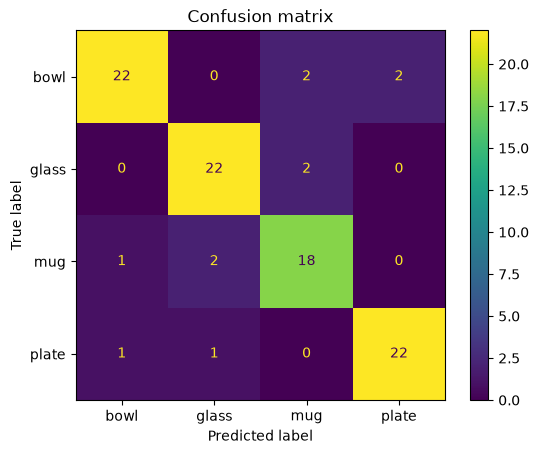

In [85]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

The classification metrics can also be calculated from the confusion matrix. The confusion matrix also shows why some classes have lower or higher precision and recall scores. The matrix shows the predcited and true labels for each input image. The model seems to predict some images depicting bowls as mugs and plates, and some mugs as glasses and bowls, explaining the lower recall scores. The lower precision score for the mug class is caused by the false predctions. The model seems to predict some bowls and glasses as mugs. The model seems to be confuse the glass and mug images.

The following code shuffles the images in the test dataset by first unbatching them and after shuffling batching them again. After obtaining the predictions, the images are displayed with their correct class labels and the probability distributions. This way the results and the performance of the model can be analysed more.

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


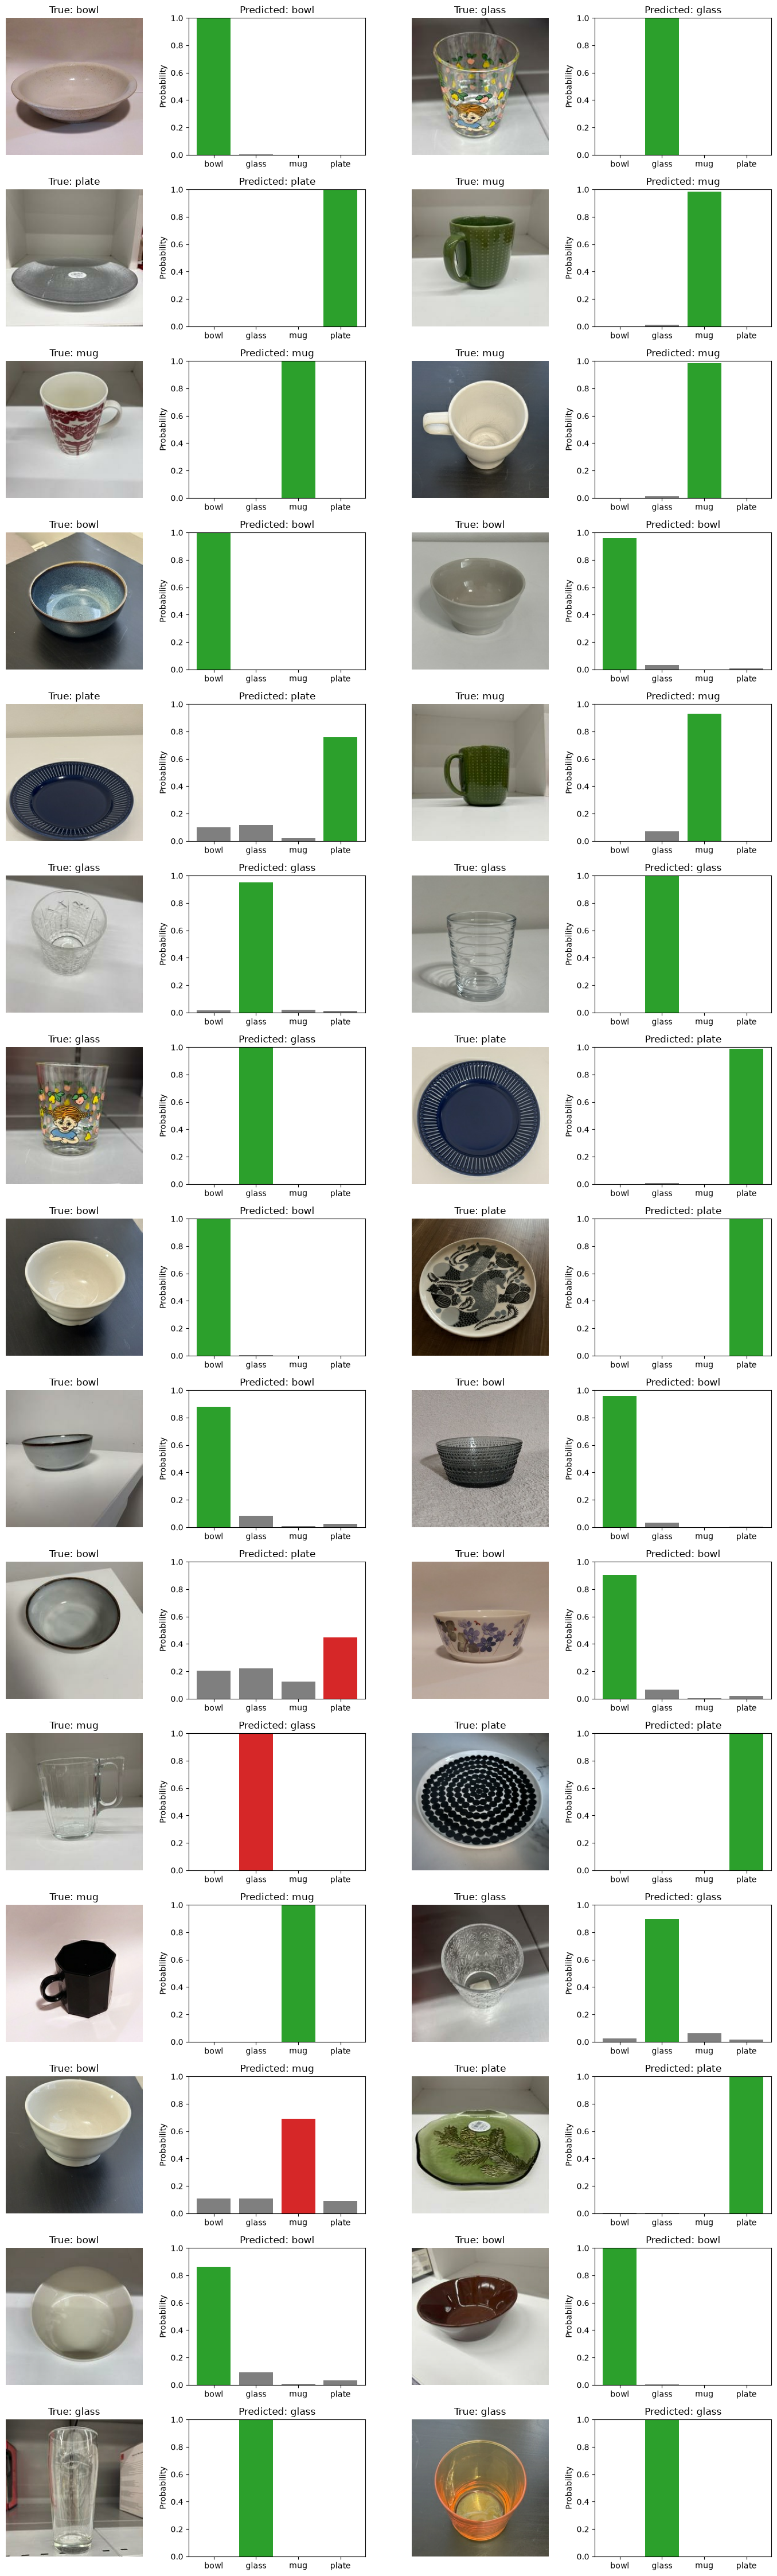

In [86]:
start = 0
images_n = 30
rows = images_n // 2

x, y = next(iter(test_dataset.unbatch().shuffle(1000).batch(images_n)))
features = conv_base.predict(keras.applications.vgg16.preprocess_input(x))
probs = test_model.predict(features)

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

The model seems to be more confident in making the predictions as the probabilties are not as spread out as they were with the original CNN model. The originally confusing images of the same blue plate are now both predicted correctly. Similarily two of the three images of the bluish gray bowl are predicted correctly. The third images where the bowl was photographed from above is predicted as plate, which is a understandable confusion. It seems that the model relaing less on the color of the item and more on the actual shape, which is a desirable outcome. 

The clear glass mug is still confusing the model. Could be that the handle blends in with the background and the model can find its shape. The taller white bowl seems to confusing too. The model might associate the taller vertical lines and the white distinct circular shape with mugs. 

The image with the floral pattern bowl is predicted correctly by this model while the original CNN model had failed to correctly identify it. The last orange yellow glass is now identified correctly while earlier it was predicted as a plate which was odd. Another drinking glass that was previously predicted as a bowl is now predicted correctly. 